In [31]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

path = '/content/drive/MyDrive/dataset_retinopathy/aptos2019-blindness-detection'
train = pd.read_csv(path + '/train.csv')

print(train.head())
print('Dataset shape:', train.shape)
print(train['diagnosis'].value_counts().sort_index())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0
Dataset shape: (3662, 2)
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


In [32]:
features = []
labels = []
missing_images = 0

for i, row in train.iterrows():
    image_path = path + '/train_images/' + row['id_code'] + '.png'

    if not os.path.exists(image_path):
        missing_images += 1
        continue

    image = Image.open(image_path).convert('RGB')
    image = image.resize((64, 64))
    pixels = np.array(image)

    red = pixels[:, :, 0]
    green = pixels[:, :, 1]
    blue = pixels[:, :, 2]

    features.append([
        red.mean(), red.std(),
        green.mean(), green.std(),
        blue.mean(), blue.std()
    ])
    labels.append(row['diagnosis'])

X = pd.DataFrame(features, columns=[
    'Red_mean', 'Red_std', 'Green_mean', 'Green_std', 'Blue_mean', 'Blue_std'
])
y = np.array(labels)

print('Feature shape:', X.shape)
print('Labels shape:', y.shape)
print('Images not found:', missing_images)
X.head()

Feature shape: (1356, 6)
Labels shape: (1356,)
Images not found: 2306


,Red_mean,Red_std,Green_mean,Green_std,Blue_mean,Blue_std
0,133.487305,70.517419,71.415039,38.582236,32.752686,21.689596
1,132.720459,69.020291,63.353027,34.651887,3.452881,8.148028
2,129.040771,68.424600,64.172119,34.162117,4.914795,8.171222
3,137.976074,72.558384,67.335693,36.668061,2.760742,7.477400
4,67.297119,40.196804,39.957764,33.223607,23.320312,21.379612


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training shape:', X_train.shape)
print('Testing shape:', X_test.shape)

Training shape: (1084, 6)
Testing shape: (272, 6)


In [34]:
#a1
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone

base_models = [
    ('lr', LogisticRegression(max_iter=1000)),
    ('dt', DecisionTreeClassifier(random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
]

final_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

stacking_rows = []

for name, final_model in final_models.items():
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('stacking', StackingClassifier(
            estimators=base_models,
            final_estimator=clone(final_model),
            cv=3
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average='weighted')
    stacking_rows.append([name, accuracy, f1])

    print(name)
    print('Accuracy:', accuracy)
    print('Weighted F1-score:', f1)
    print()

a1_table = pd.DataFrame(stacking_rows, columns=['Final estimator', 'Accuracy', 'Weighted F1'])
print(a1_table)

Logistic Regression
Accuracy: 0.8529411764705882
Weighted F1-score: 0.823049183228667

Decision Tree
Accuracy: 0.7683823529411765
Weighted F1-score: 0.767953728562685

Random Forest
Accuracy: 0.8382352941176471
Weighted F1-score: 0.8125257928370087

KNN
Accuracy: 0.8308823529411765
Weighted F1-score: 0.809451816069463

       Final estimator  Accuracy  Weighted F1
0  Logistic Regression  0.852941     0.823049
1        Decision Tree  0.768382     0.767954
2        Random Forest  0.838235     0.812526
3                  KNN  0.830882     0.809452


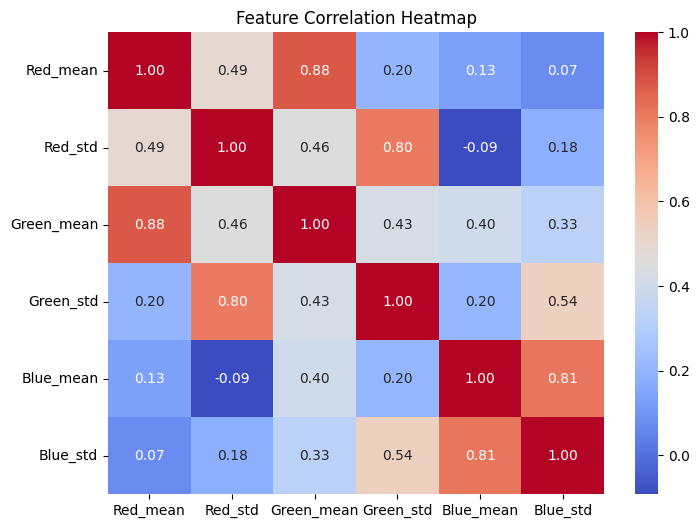

In [35]:
#a2
correlation = X.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

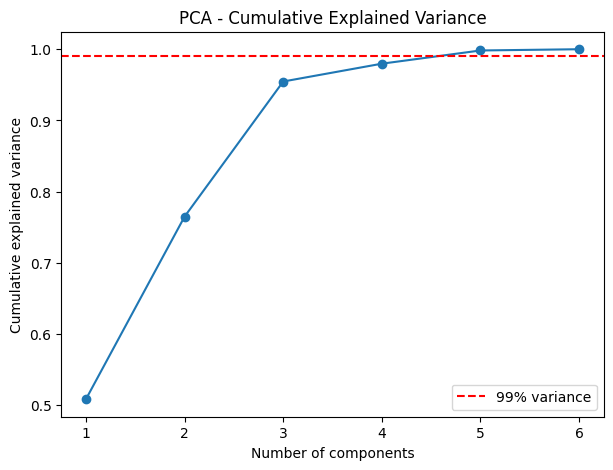

Components needed for 99% variance: 5
Original number of features: 6


In [36]:
#a3
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

pca_full = PCA()
pca_full.fit(X_train_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = np.argmax(cumulative_variance >= 0.99) + 1

plt.figure(figsize=(7, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axhline(0.99, color='red', linestyle='--', label='99% variance')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA - Cumulative Explained Variance')
plt.legend()
plt.show()

print('Components needed for 99% variance:', n_comp)
print('Original number of features:', X_train.shape[1])

In [37]:
#comparing results
comparison_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Stacking (Logistic Regression meta)': StackingClassifier(
        estimators=base_models,
        final_estimator=LogisticRegression(max_iter=1000),
        cv=3
    )
}

pca_rows = []

for name, classifier in comparison_models.items():
    original_model = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', clone(classifier))
    ])

    pca_model = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_comp)),
        ('classifier', clone(classifier))
    ])

    original_model.fit(X_train, y_train)
    original_predictions = original_model.predict(X_test)

    pca_model.fit(X_train, y_train)
    pca_predictions = pca_model.predict(X_test)

    pca_rows.append([
        name, 'Original', accuracy_score(y_test, original_predictions),
        f1_score(y_test, original_predictions, average='weighted')
    ])
    pca_rows.append([
        name, 'PCA', accuracy_score(y_test, pca_predictions),
        f1_score(y_test, pca_predictions, average='weighted')
    ])

comparison_table = pd.DataFrame(
    pca_rows, columns=['Model', 'Features', 'Accuracy', 'Weighted F1']
)
print(comparison_table)

                                 Model  Features  Accuracy  Weighted F1
0                  Logistic Regression  Original  0.823529     0.776356
1                  Logistic Regression       PCA  0.819853     0.767869
2                        Decision Tree  Original  0.801471     0.798762
3                        Decision Tree       PCA  0.819853     0.818778
4                        Random Forest  Original  0.856618     0.826772
5                        Random Forest       PCA  0.856618     0.831606
6  Stacking (Logistic Regression meta)  Original  0.852941     0.823049
7  Stacking (Logistic Regression meta)       PCA  0.871324     0.842916
